---
title: 'Solutions: Introduction to Transformers'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *Introduction to Transformers*.

In [8]:
import copy
import math
import random
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split

plt.style.use("seaborn-v0_8")
torch.set_float32_matmul_precision("high")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)

### Exercise 1: Why divide by $\sqrt{d_k}$?

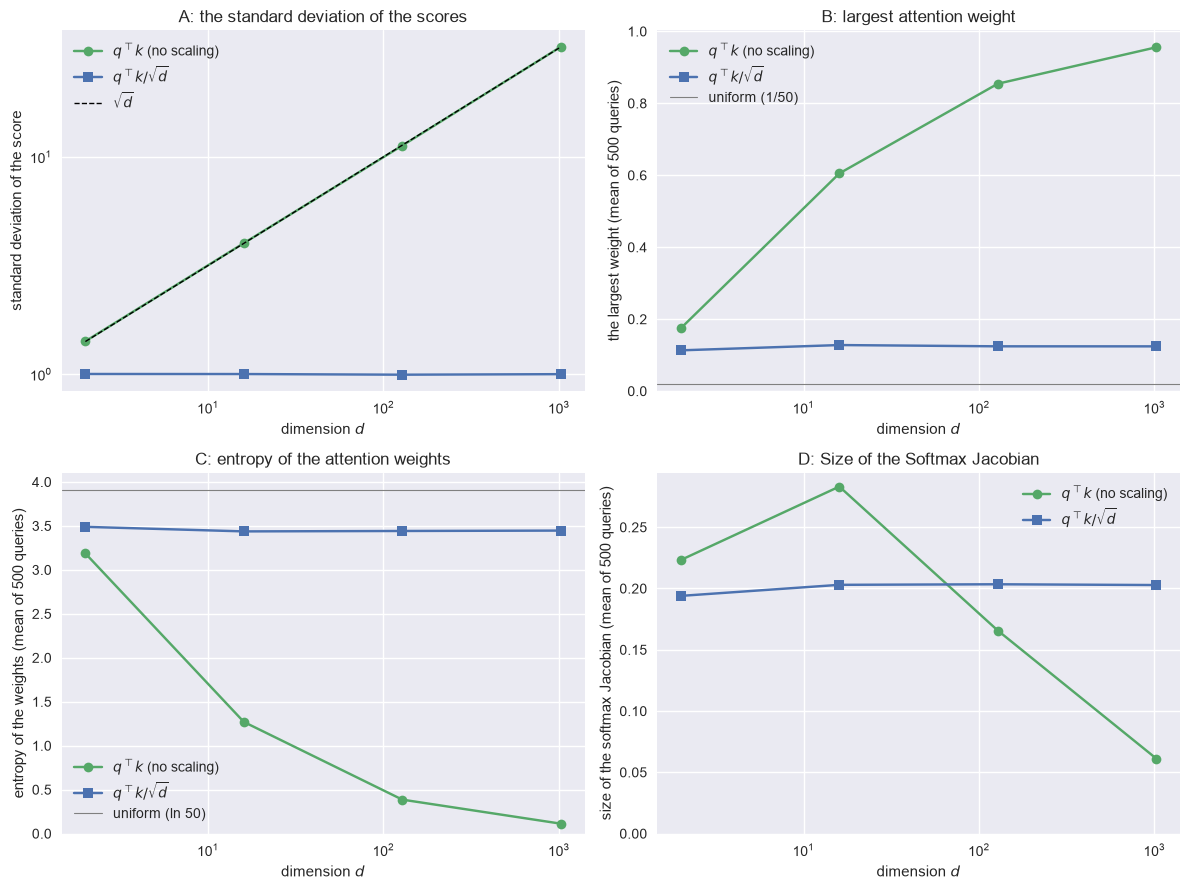

Standard deviation of q.k: d = 2: 1.42, d = 16: 4.01, d = 128: 11.26, d = 1024: 32.04
Standard deviation of q.k / sqrt(d): d = 2: 1.00, d = 16: 1.00, d = 128: 1.00, d = 1024: 1.00
No scaling: d = 2: largest 0.17, entropy 3.19, Jacobian 0.223; d = 16: largest 0.61, entropy 1.27, Jacobian 0.283; d = 128: largest 0.85, entropy 0.39, Jacobian 0.166; d = 1024: largest 0.96, entropy 0.11, Jacobian 0.061
Divided by sqrt(d): d = 2: largest 0.11, entropy 3.49, Jacobian 0.194; d = 16: largest 0.13, entropy 3.44, Jacobian 0.203; d = 128: largest 0.12, entropy 3.44, Jacobian 0.203; d = 1024: largest 0.12, entropy 3.45, Jacobian 0.203


In [9]:
# Figure for Exercise 1: why the attention scores are divided by sqrt(d_k). No training, only random vectors.
EX1_DIMS = [2, 16, 128, 1024]   # key dimensions d_k to compare; feel free to change them
EX1_KEYS = 50                   # keys per query
EX1_QUERIES = 500               # queries per dimension; the panels show averages over these
EX1_SEED = 0
ex1_rng = np.random.default_rng(EX1_SEED)


def ex1_softmax(s):
    e = np.exp(s - s.max())
    return e / e.sum()


def ex1_weight_stats(a):
    """Largest weight, entropy, and the size of the softmax Jacobian diag(a) - a a^T."""
    entropy = -np.sum(a * np.log(a + 1e-300))
    jacobian = np.diag(a) - np.outer(a, a)
    return a.max(), entropy, np.linalg.norm(jacobian)


# (a) spread of q.k for random q and k with independent N(0, 1) entries
ex1_spread = {"raw": [], "scaled": []}
for d in EX1_DIMS:
    q = ex1_rng.standard_normal((20000, d))
    k = ex1_rng.standard_normal((20000, d))
    dots = np.sum(q * k, axis=1)
    ex1_spread["raw"].append(dots.std())
    ex1_spread["scaled"].append((dots / np.sqrt(d)).std())

# (b) one query against EX1_KEYS keys, with and without the division by sqrt(d)
ex1_stats = {"raw": [], "scaled": []}
for d in EX1_DIMS:
    rows = {"raw": [], "scaled": []}
    for t in range(EX1_QUERIES):
        q = ex1_rng.standard_normal(d)
        K = ex1_rng.standard_normal((EX1_KEYS, d))
        s = K @ q
        for name, scores in [("raw", s), ("scaled", s / np.sqrt(d))]:
            a = ex1_softmax(scores)
            rows[name].append(ex1_weight_stats(a))
    for name in rows:
        ex1_stats[name].append(np.mean(rows[name], axis=0))
ex1_stats = {name: np.array(v) for name, v in ex1_stats.items()}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
dims = np.array(EX1_DIMS)
styles = {"raw": ("o-", "C1", r"$q^\top k$ (no scaling)"), "scaled": ("s-", "C0", r"$q^\top k / \sqrt{d}$")}

ax = axes[0, 0]
for name, (fmt, color, label) in styles.items():
    ax.loglog(dims, ex1_spread[name], fmt, color=color, label=label)
ax.loglog(dims, np.sqrt(dims), "k--", lw=1, label=r"$\sqrt{d}$")
ax.set_xlabel("dimension $d$")
ax.set_ylabel("standard deviation of the score")
ax.set_title("A: the standard deviation of the scores")
ax.legend()

panels = [
    (axes[0, 1], 0, "the largest weight", "B: largest attention weight", 1 / EX1_KEYS, "uniform (1/50)"),
    (axes[1, 0], 1, "entropy of the weights", "C: entropy of the attention weights", np.log(EX1_KEYS), "uniform (ln 50)"),
    (axes[1, 1], 2, "size of the softmax Jacobian", "D: Size of the Softmax Jacobian", None, None),
]
for ax, col, ylabel, title, ref, ref_label in panels:
    for name, (fmt, color, label) in styles.items():
        ax.semilogx(dims, ex1_stats[name][:, col], fmt, color=color, label=label)
    if ref is not None:
        ax.axhline(ref, color="gray", lw=0.8, label=ref_label)
    ax.set_xlabel("dimension $d$")
    ax.set_ylabel(ylabel + f" (mean of {EX1_QUERIES} queries)")
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.legend()

plt.tight_layout()
plt.show()

print("Standard deviation of q.k:", ", ".join(f"d = {d}: {s:.2f}" for d, s in zip(EX1_DIMS, ex1_spread["raw"])))
print("Standard deviation of q.k / sqrt(d):", ", ".join(f"d = {d}: {s:.2f}" for d, s in zip(EX1_DIMS, ex1_spread["scaled"])))
for name in ["raw", "scaled"]:
    print(f"{'No scaling' if name == 'raw' else 'Divided by sqrt(d)'}: " + "; ".join(
        f"d = {d}: largest {m:.2f}, entropy {h:.2f}, Jacobian {j:.3f}" for d, (m, h, j) in zip(EX1_DIMS, ex1_stats[name])))

In [10]:
print(f"Uniform weights: largest {1 / EX1_KEYS:.3f}, entropy ln 50 = {np.log(EX1_KEYS):.2f}, "
      f"Jacobian {np.linalg.norm(np.eye(EX1_KEYS) / EX1_KEYS - 1 / EX1_KEYS ** 2):.3f}")
# Jacobian of a softmax with one weight near 1
a = ex1_softmax(np.array([8.0] + [0.0] * (EX1_KEYS - 1)))
print(f"One weight {a.max():.3f}: Jacobian {np.linalg.norm(np.diag(a) - np.outer(a, a)):.3f}")

Uniform weights: largest 0.020, entropy ln 50 = 3.91, Jacobian 0.140
One weight 0.984: Jacobian 0.016


**(a)** The score is a sum of $d$ products, $q^\top k = \sum_{m=1}^{d} q_m k_m$. Each product has mean 0 and variance 1, and the $d$ products are independent. Variances of independent terms add, so the variance of the sum is $d$ and its standard deviation is $\sqrt{d}$. The figure gives 1.42, 4.01, 11.26 and 32.04 for $d$ = 2, 16, 128 and 1024, against $\sqrt{d}$ = 1.41, 4, 11.31 and 32. Dividing a random number by $\sqrt{d}$ divides its standard deviation by $\sqrt{d}$, so the scaled score has standard deviation 1 for every $d$ (1.00 in all four cases). The entries of a trained network's queries and keys are not standard normal, but the score is still a sum of $d$ terms. So the division keeps the scores in the same range whatever $d_k$ we choose.

::: {.callout-note collapse="true"}
### Derivation of the variance of $q^\top k$
For one term, $q_m$ and $k_m$ are independent with mean 0 and variance 1, so $\mathbb{E}[q_m k_m] = \mathbb{E}[q_m]\,\mathbb{E}[k_m] = 0$ and $\text{Var}(q_m k_m) = \mathbb{E}[q_m^2 k_m^2] = \mathbb{E}[q_m^2]\,\mathbb{E}[k_m^2] = 1$. The $d$ terms are independent, so

$$
\text{Var}\left(q^\top k\right) = \sum_{m=1}^{d} \text{Var}(q_m k_m) = d,
\qquad
\text{Var}\left(\frac{q^\top k}{\sqrt{d}}\right) = \frac{d}{d} = 1.
$$
:::

**(b)** Without the scaling, the scores at $d$ = 1024 have a spread of about 32. The largest of 50 such scores is then far above the second largest, and the softmax turns that gap into a weight of nearly 1. On average the largest weight is 0.96 and the entropy is 0.11, against $\ln 50 \approx 3.91$ for equal weights. So attention becomes a hard lookup of a single key. The other points no longer contribute to $z_i$.

This is bad for learning. The softmax Jacobian is $\text{diag}(a) - a a^\top$. When one weight is near 1 and all others are near 0, every entry of this matrix is near 0. For example, the diagonal entries are $a_j(1 - a_j)$. So a small change of a score hardly changes the weights. The gradient that reaches $W_Q$ and $W_K$ passes through this Jacobian, so it is small too: 0.06 at $d$ = 1024, against 0.20 with the scaling. Gradient descent then gets almost no signal about which other keys the query should attend to, and the query stays stuck on the key that happened to win at the start.

**(c)** The Jacobian is small at both ends. With equal weights it is 0.14, and with one weight near 1 it goes to 0. It is largest in between, when a few keys share most of the weight. Without the scaling, the weights at $d$ = 2 and 16 are sharper than with the scaling but not yet one-hot (largest weight 0.17 and 0.61). That is closer to this middle, so the Jacobian is larger: 0.22 and 0.28, against 0.19 and 0.20 with the scaling. Only at large $d$ do the weights become one-hot, and the Jacobian falls to 0.17 at $d$ = 128 and 0.06 at $d$ = 1024.

So the scaling does not always give larger gradients. The scaling makes the sharpness of attention independent of $d$. With the scaling, the largest weight (0.11 to 0.13), the entropy (3.44 to 3.49) and the Jacobian (0.19 to 0.20) hardly change from $d$ = 2 to $d$ = 1024. Without it, all three depend strongly on $d$. When we build a transformer we choose $d_k$ freely, and we want the same initialization and the same learning rate to work for any choice. With the scaling, attention starts out equally sharp, and the gradients through the softmax have about the same size, whatever $d_k$ is.

### Exercise 2: How the cost grows with the number of points

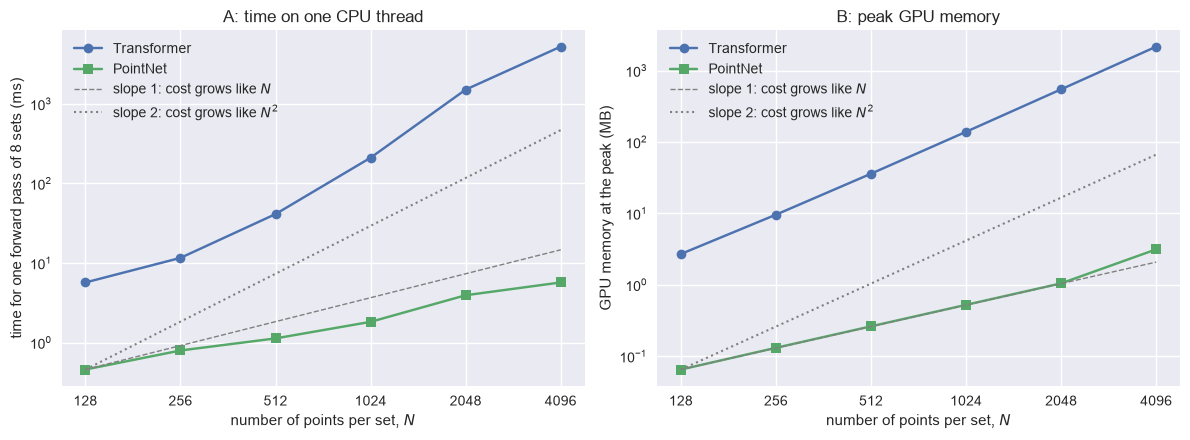

      model  n_points  cpu_time_ms   gpu_mb
Transformer       128        5.693    2.700
Transformer       256       11.601    9.598
Transformer       512       41.203   35.979
Transformer      1024      210.560  139.071
Transformer      2048     1512.363  547.236
Transformer      4096     5250.792 2168.219
   PointNet       128        0.458    0.065
   PointNet       256        0.795    0.131
   PointNet       512        1.128    0.262
   PointNet      1024        1.822    0.524
   PointNet      2048        3.934    1.048
   PointNet      4096        5.700    3.136


In [11]:
# Figure for Exercise 2: measured cost of one forward pass against the number of points N
# Precomputed timings of the chapter's 3D-sized models (one CPU thread, fastest of 15 runs),
# and their peak GPU memory minus what a set with a single point already needs
COST_CSV = "../data/transformers_cost.csv"
# If you don't have the data folder locally (for example on Google Colab), load the GitHub copy instead:
# COST_CSV = "https://raw.githubusercontent.com/IDEALLab/ML4ME_Textbook/main/data/transformers_cost.csv"
cost = pd.read_csv(COST_CSV)
cost_models = [("Transformer", "o-", "C0"), ("PointNet", "s-", "C1")]
n_ref = np.array([128, 4096], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, ylabel, title in [
    (axes[0], "cpu_time_ms", "time for one forward pass of 8 sets (ms)", "A: time on one CPU thread"),
    (axes[1], "gpu_mb", "GPU memory at the peak (MB)", "B: peak GPU memory"),
]:
    for name, fmt, color in cost_models:
        sub = cost[cost.model == name]
        ax.loglog(sub.n_points, sub[column], fmt, color=color, label=name)
    # Gray guide lines with slope 1 and slope 2, to compare the curves against
    y0 = cost[column].min()
    ax.loglog(n_ref, y0 * (n_ref / n_ref[0]), "--", color="gray", lw=1, label="slope 1: cost grows like $N$")
    ax.loglog(n_ref, y0 * (n_ref / n_ref[0]) ** 2, ":", color="gray", lw=1.5, label="slope 2: cost grows like $N^2$")
    ax.set_xlabel("number of points per set, $N$")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(cost.n_points.unique()))
    ax.set_xticklabels([str(n) for n in sorted(cost.n_points.unique())])
    ax.minorticks_off()
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()
print(cost.to_string(index=False))

In [12]:
cost = pd.read_csv("../data/transformers_cost.csv")
print(cost.to_string(index=False))

fits = {}
for name in ["Transformer", "PointNet"]:
    sub = cost[cost.model == name].sort_values("n_points")
    big = sub[sub.n_points >= 512]
    for column in ["cpu_time_ms", "gpu_mb"]:
        slope, intercept = np.polyfit(np.log(big.n_points), np.log(big[column]), 1)
        fits[(name, column)] = slope
        local = np.diff(np.log(sub[column].values)) / np.diff(np.log(sub.n_points.values))
        ratios = sub[column].values[1:] / sub[column].values[:-1]
        print(f"{name:11s} {column:11s}: slope of the fit for N >= 512 = {slope:.2f}; "
              f"slopes between neighbors {np.round(local, 2).tolist()}; ratio when N doubles {np.round(ratios, 1).tolist()}")

# (b) Extrapolate from N = 4096 to a scan with 100,000 points
n_scan, n_last = 100_000, 4096
t_last = cost[(cost.model == "Transformer") & (cost.n_points == n_last)].cpu_time_ms.item() / 1e3  # seconds
for p in [2.0, fits[("Transformer", "cpu_time_ms")]]:
    t_scan = t_last * (n_scan / n_last) ** p
    print(f"slope {p:.2f}: a batch of 8 scans takes about {t_scan:,.0f} s = {t_scan / 3600:.1f} h, "
          f"or {t_scan / 8 / 60:.0f} min per scan")
mem_last = cost[(cost.model == "Transformer") & (cost.n_points == n_last)].gpu_mb.item()
print(f"GPU memory of the batch from the slope-2 fit: about {mem_last * (n_scan / n_last) ** 2 / 1e6:.1f} TB")
print(f"one attention matrix, one set, one layer: {n_scan ** 2:.1e} numbers x 4 bytes = {n_scan ** 2 * 4 / 1e9:.0f} GB")
print(f"the same at N = {n_last}: {n_last ** 2 * 4 / 1e6:.0f} MB, so 8 sets need {8 * n_last ** 2 * 4 / 1e6:.0f} MB per layer")

      model  n_points  cpu_time_ms   gpu_mb
Transformer       128        5.693    2.700
Transformer       256       11.601    9.598
Transformer       512       41.203   35.979
Transformer      1024      210.560  139.071
Transformer      2048     1512.363  547.236
Transformer      4096     5250.792 2168.219
   PointNet       128        0.458    0.065
   PointNet       256        0.795    0.131
   PointNet       512        1.128    0.262
   PointNet      1024        1.822    0.524
   PointNet      2048        3.934    1.048
   PointNet      4096        5.700    3.136
Transformer cpu_time_ms: slope of the fit for N >= 512 = 2.38; slopes between neighbors [1.03, 1.83, 2.35, 2.84, 1.8]; ratio when N doubles [2.0, 3.6, 5.1, 7.2, 3.5]
Transformer gpu_mb     : slope of the fit for N >= 512 = 1.97; slopes between neighbors [1.83, 1.91, 1.95, 1.98, 1.99]; ratio when N doubles [3.6, 3.7, 3.9, 3.9, 4.0]
PointNet    cpu_time_ms: slope of the fit for N >= 512 = 0.81; slopes between neighbors [0.8, 0

**(a)** For $N \geq 512$, the transformer's time grows with a slope of about 2.4, and its memory with a slope of 1.97. PointNet's time grows with a slope of about 0.8, and its memory with a slope of 1.17. So PointNet costs about $N^1$ and the transformer about $N^2$.

PointNet runs the same small MLP on each point and then takes a maximum over the points. Each point costs the same, so the work and the stored features grow like $N$. Most of the transformer also works point by point: the input projection, the queries, keys and values, and the small MLP. But the scores $Q K^\top$ compare every point with every other point. That is $N^2$ dot products, and the $N \times N$ matrix of scores and weights must be stored. The weighted sum $A V$ also takes $N^2$ products. For large $N$ these steps dominate. At $N$ = 4096, one attention matrix for one set has $4097^2$ numbers (4096 points plus the CLS token), or 67 MB, and the batch of 8 sets needs 537 MB. The measured peak of 2168 MB is about four such arrays, for example the scores, the masked scores and the weights.

The memory panel follows a straight line much more closely. The slopes between neighboring points of the transformer's memory are 1.83, 1.91, 1.95, 1.98 and 1.99, and PointNet's memory has slope 1.0 up to $N$ = 2048. Memory is set by the sizes of the arrays the forward pass creates, so it is the same in every run and follows the count of numbers stored. The time also includes costs that do not grow with $N$, such as starting each operation, which dominate at small $N$. It further depends on whether the data fit in the processor's cache, and on what else the computer is doing. So the slopes of the time curves jump around: 1.03, 1.83, 2.35, 2.84 and 1.80 for the transformer, and between 0.5 and 1.1 for PointNet. The jump to 2.84 between 1024 and 2048 points probably comes when the $N \times N$ matrices no longer fit in the cache.
If we double $N$, the transformer takes about 4 times longer and PointNet about 2 times longer. The measured ratios are noisier: 7.2 and 3.5 for the transformer's last two doublings, and between 1.4 and 2.2 for PointNet. The memory ratios are 3.9 and 4.0 for the transformer's last two doublings.

**(b)** A scan with 100,000 points has $100{,}000 / 4096 \approx 24.4$ times more points than our largest set. With a slope of 2, the time grows by $24.4^2 \approx 600$. A batch of 8 scans then takes about $5.25 \text{ s} \times 600 \approx 3{,}100$ s, close to an hour, or about 6.5 minutes per scan. With the fitted slope of 2.4, it takes about 3 hours. One attention matrix has $10^5 \times 10^5 = 10^{10}$ numbers. At 4 bytes each, that is 40 GB for one set and one layer. Our model has 3 layers, and training keeps the matrices of every layer for the backward pass. So one scan needs more than 100 GB just for attention, more than a single GPU holds.

There are several things we could do instead. We could subsample each scan to a few thousand points, at random or spread evenly over the surface, if the task needs only the coarse shape. We could let each point attend only to its $k$ nearest neighbors, which costs about $N k$ instead of $N^2$. We could let the points attend to a small set of $m$ learned summary tokens, which costs about $N m$. Or we could use PointNet when the task does not need relations between points.

::: {.callout-note collapse="true"}
### Code that measured the timings for Exercise 2
We ran this code once, with the chapter's `SetTransformer` and `PointNetClassifier` defined, and saved the table to `transformers_cost.csv` in the `data` folder. The computer had an Intel Core Ultra laptop processor (one thread used) and an NVIDIA GeForce RTX 4050 Laptop GPU.

```python
import time

N_POINTS = [128, 256, 512, 1024, 2048, 4096]
BATCH = 8          # sets per forward pass
REPEATS = 15       # we keep the fastest of these runs for each N
CPU_THREADS = 1    # a fixed thread count makes the CPU timings comparable


def make_cost_models(device):
    """The chapter's 3D-sized models (same sizes as transformer_cloud and pointnet), untrained."""
    torch.manual_seed(0)
    transformer = SetTransformer(input_dim=3, num_classes=4, d_model=15, num_layers=3, dim_feedforward=20, dropout=0.0)
    pointnet = PointNetClassifier(num_classes=4, widths=(16, 16, 16), dropout=0.0)
    return {"Transformer": transformer.to(device).eval(), "PointNet": pointnet.to(device).eval()}


def forward_once(name, model, x, mask):
    if name == "Transformer":
        return model(x, src_key_padding_mask=mask)
    return model(x)


def cpu_times_ms(name, model):
    """Fastest of REPEATS forward passes of BATCH random sets, for every n in N_POINTS, in milliseconds.

    The repeats go round all n in turn, so a slow moment of the computer does not hit only one n.
    """
    inputs = {n: (torch.randn(BATCH, n, 3), torch.zeros(BATCH, n, dtype=torch.bool)) for n in N_POINTS}
    best = {n: float("inf") for n in N_POINTS}
    with torch.no_grad():
        for n in N_POINTS:
            forward_once(name, model, *inputs[n])  # warm-up
        for _ in range(REPEATS):
            for n in N_POINTS:
                t0 = time.perf_counter()
                forward_once(name, model, *inputs[n])
                best[n] = min(best[n], time.perf_counter() - t0)
    return {n: 1e3 * t for n, t in best.items()}


def gpu_peak_mb(name, model, n):
    """Extra GPU memory at the peak of one forward pass, in megabytes."""
    device = torch.device("cuda")
    x = torch.randn(BATCH, n, 3, device=device)
    mask = torch.zeros(BATCH, n, dtype=torch.bool, device=device)
    with torch.no_grad():
        forward_once(name, model, x, mask)  # warm-up, so one-time allocations are not counted
    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated()
    with torch.no_grad():
        forward_once(name, model, x, mask)
    torch.cuda.synchronize()
    return (torch.cuda.max_memory_allocated() - base) / 1e6


def measure_cost():
    torch.set_num_threads(CPU_THREADS)
    cpu_models = make_cost_models(torch.device("cpu"))
    gpu_models = make_cost_models(torch.device("cuda")) if torch.cuda.is_available() else None
    rows = []
    for name, model in cpu_models.items():
        times = cpu_times_ms(name, model)
        # Memory that one forward pass needs even for a single point; we subtract it below
        fixed_mb = gpu_peak_mb(name, gpu_models[name], 1) if gpu_models is not None else np.nan
        for n in N_POINTS:
            row = {"model": name, "n_points": n, "cpu_time_ms": times[n]}
            row["gpu_mb"] = gpu_peak_mb(name, gpu_models[name], n) - fixed_mb if gpu_models is not None else np.nan
            rows.append(row)
            print(row, flush=True)
    return pd.DataFrame(rows)


cost = measure_cost()
cost.to_csv("../data/transformers_cost.csv", index=False)
```
:::

### Exercise 3: What does one attention block add to PointNet?

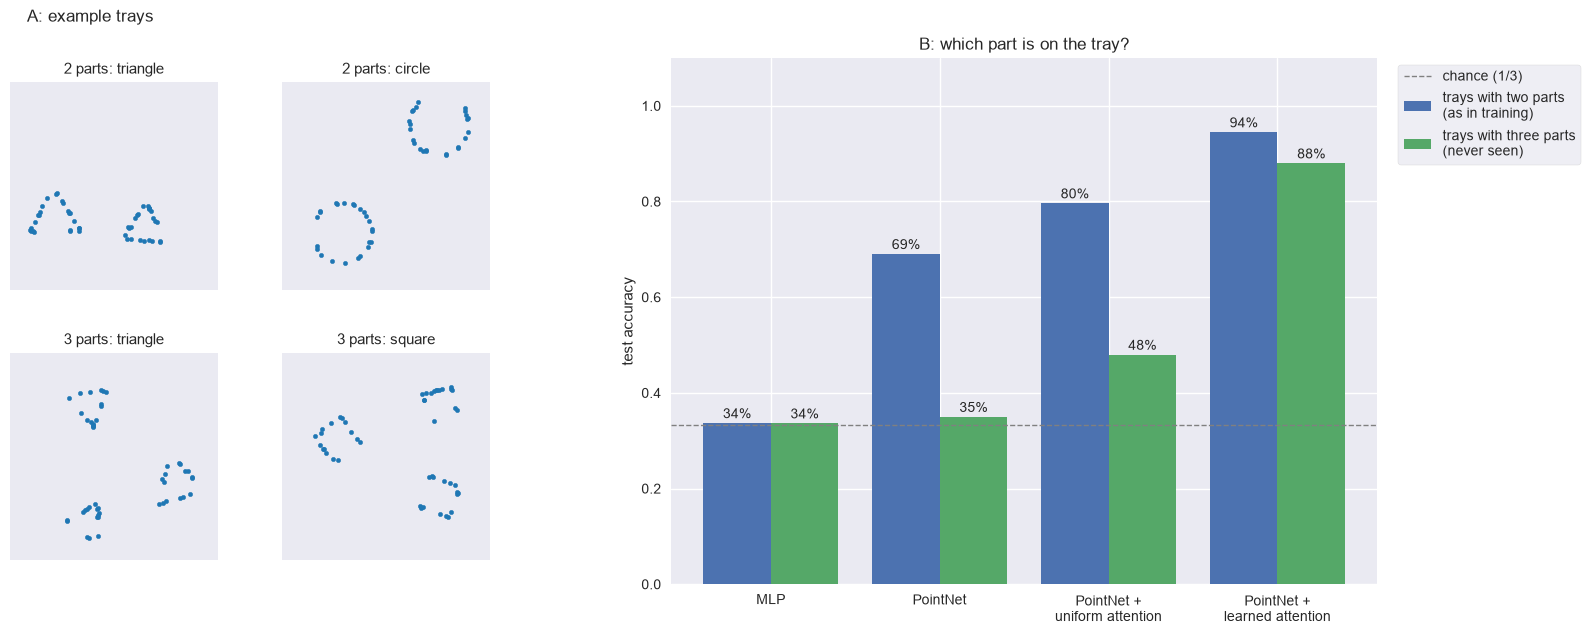

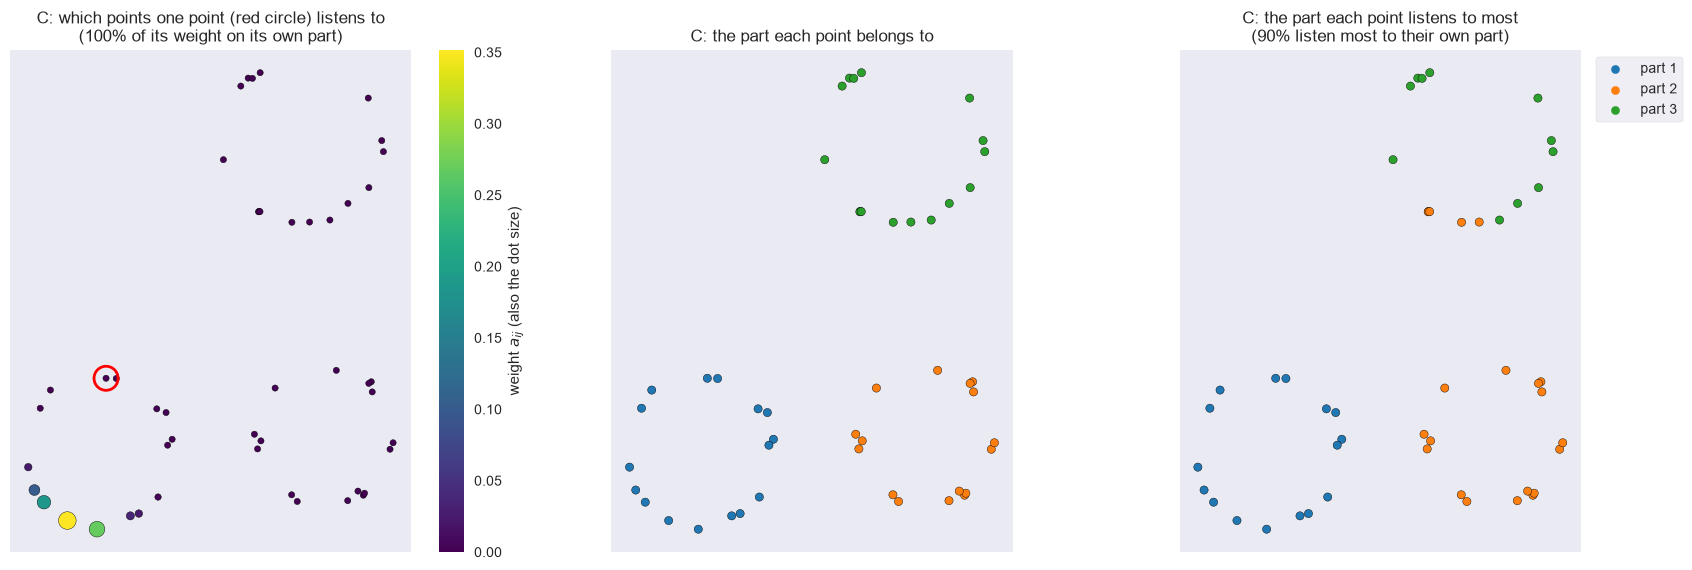

Share of a point's weight that lands on its own part, over 500 trays:
  two parts: 0.95 (chance 0.50)
  three parts: 0.90 (chance 0.33)


In [13]:
# Figure for Exercise 3: trays with two or three copies of one part (precomputed results)
trays = np.load("../data/transformers_trays.npz")
model_names = [str(n) for n in trays["model_names"]]
part_names = ["circle", "square", "triangle"]

# Panels A and B: example trays and accuracies
fig = plt.figure(figsize=(16, 6.5))
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 0.25, 3.4])
examples = [("examples_two", "labels_two", 0, 2), ("examples_two", "labels_two", 1, 2),
            ("examples_three", "labels_three", 0, 3), ("examples_three", "labels_three", 1, 3)]
for k, (key, label_key, idx, n_parts) in enumerate(examples):
    ax = fig.add_subplot(grid[k // 2, k % 2])
    tray = trays[key][idx]
    ax.scatter(tray[:, 0], tray[:, 1], s=10, c="tab:blue")
    ax.set_title(f"{n_parts} parts: {part_names[trays[label_key][idx]]}", fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-3.4, 3.4)
    ax.set_ylim(-3.4, 3.4)
    ax.set_xticks([])
    ax.set_yticks([])
fig.text(0.02, 0.97, "A: example trays", fontsize=12, va="top")
ax = fig.add_subplot(grid[:, 3])
x = np.arange(len(model_names))
bars_two = ax.bar(x - 0.2, trays["acc_two"], 0.4, label="trays with two parts\n(as in training)")
bars_three = ax.bar(x + 0.2, trays["acc_three"], 0.4, label="trays with three parts\n(never seen)")
for bar in list(bars_two) + list(bars_three):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.0%}", ha="center", fontsize=10)
ax.axhline(1 / 3, color="gray", ls="--", lw=1, label="chance (1/3)")
ax.set_xticks(x)
ax.set_xticklabels([name.replace("PointNet with\n", "PointNet +\n") for name in model_names], fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_ylabel("test accuracy")
ax.set_title("B: which part is on the tray?")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

# Panel C: where the points listen to, in one tray with three parts (the learned attention block)
tray = 14
points, ids, A_tray = trays["trays_three"][tray], trays["ids_three"][tray], trays["attention_three"][tray]
members = np.where(ids == 0)[0]
own_shares = A_tray[members][:, ids == 0].sum(axis=1)
query = members[np.argsort(own_shares)[len(members) // 2]]  # a typical point: median share on its own part
listens_to = np.argmax([A_tray[:, ids == part].sum(axis=1) for part in range(3)], axis=0)
part_colors = np.array(["tab:blue", "tab:orange", "tab:green"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
sc = axes[0].scatter(points[:, 0], points[:, 1], c=A_tray[query], cmap="viridis", vmin=0, s=20 + 400 * A_tray[query],
                     edgecolors="k", linewidths=0.3, zorder=3)
axes[0].scatter(*points[query], s=300, facecolors="none", edgecolors="red", linewidths=2, zorder=4)
fig.colorbar(sc, ax=axes[0], label=r"weight $a_{ij}$ (also the dot size)")
axes[0].set_title(f"C: which points one point (red circle) listens to\n({A_tray[query, ids == 0].sum():.0%} of its weight on its own part)")
axes[1].scatter(points[:, 0], points[:, 1], c=part_colors[ids], s=35, edgecolors="k", linewidths=0.3)
axes[1].set_title("C: the part each point belongs to")
axes[2].scatter(points[:, 0], points[:, 1], c=part_colors[listens_to], s=35, edgecolors="k", linewidths=0.3)
axes[2].set_title(f"C: the part each point listens to most\n({np.mean(listens_to == ids):.0%} listen most to their own part)")
for part in range(3):
    axes[2].scatter([], [], c=part_colors[part], s=35, label=f"part {part + 1}")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
print("Share of a point's weight that lands on its own part, over 500 trays:")
print(f"  two parts: {trays['share_two']:.2f} (chance 0.50)")
print(f"  three parts: {trays['share_three']:.2f} (chance 0.33)")

In [14]:
# More numbers from the same runs (saved in transformers_trays.npz)
for name, n, two, three in zip(trays["model_names"], trays["n_params"], trays["acc_two"], trays["acc_three"]):
    print(f"{str(name).replace(chr(10), ' '):32s} {n:6,d} parameters: two parts {two:.1%}, three parts {three:.1%}")
print(f"Wide PointNet on centered trays ({int(trays['wide_params']):,} parameters, 100 epochs):")
print(f"  two parts {trays['wide_pointnet'][0]:.1%}, three parts {trays['wide_pointnet'][1]:.1%}")
print("PointNet with learned attention, but mean pooling instead of max pooling:")
print(f"  two parts {trays['mean_pool'][0]:.1%}, three parts {trays['mean_pool'][1]:.1%}")
print("Trays with three parts and 24 points per part (72 points):")
print(f"  PointNet {trays['three_72'][0]:.1%}, PointNet with attention {trays['three_72'][1]:.1%}")

MLP                              66,179 parameters: two parts 33.7%, three parts 33.7%
PointNet                         46,979 parameters: two parts 69.0%, three parts 35.0%
PointNet with uniform attention  56,259 parameters: two parts 79.7%, three parts 48.0%
PointNet with learned attention  56,259 parameters: two parts 94.5%, three parts 88.0%
Wide PointNet on centered trays (298,883 parameters, 100 epochs):
  two parts 90.6%, three parts 36.5%
PointNet with learned attention, but mean pooling instead of max pooling:
  two parts 72.8%, three parts 34.1%
Trays with three parts and 24 points per part (72 points):
  PointNet 33.7%, PointNet with attention 96.2%


**(a)** Yes. PointNet computes the feature of a point from that point alone, so the same point gets the same feature in every tray. After the max pooling, PointNet knows which regions of the tray hold points, but not which points belong to the same part. In panel B it reaches 69% on trays with two parts and falls to 35% on trays with three parts, close to guessing among the three kinds of part (33%). The model with attention, which can group the points, reaches 94% and 88%. The numbers above show that a much wider PointNet does not help on trays with three parts (36.5%), and neither do more points per part (33.7%).

**(b)** Almost every point gives most of its weight to its own part: on average 95% of the weight on trays with two parts and 90% on trays with three (printed under the figure). So $z_i$ is mostly an average of the values of its own part, and $h_i = x_i + z_i$ tells the PointNet that follows not only where the point is but also something about the part it belongs to. PointNet alone cannot compute this, because it looks at each point on its own. A third part changes little for the points of the other parts, because they keep listening to their own part. So the model still reaches 88% on trays with three parts.

**(c)** Every point gives the same weight, $1/48$, to every point, so every point receives the same thing: the average of the values over the whole tray. This average still describes the whole tray, so this model does somewhat better than PointNet alone (80% against 69% on two parts). But it is the same for all points of the tray, so it cannot tell a point which part it belongs to. On trays with three parts it reaches only 48%, against 88% with learned attention.

**(d)** For 48 strain gauges at fixed places, the input always has the same size and order: entry 17 is always the same gauge. An MLP can use this directly, and it is the cheapest choice. For a scan of one bracket where only the overall shape matters, the order of the points means nothing, and the shape can be read from the points one at a time. PointNet does this, and its cost grows like $N$ (Exercise 2). For the trays, the points have to be compared with each other to find which points form a part. Of the three models, only the one with attention does this. With 48 points there are only $48^2 = 2304$ pairs, so the $N^2$ cost does not matter here.

::: {.callout-note collapse="true"}
### Code that trained the models for Exercise 3
We ran this code once, with the chapter's `ShapeMLP`, `SelfAttentionBlock` and `PointNetClassifier` defined, on an NVIDIA GeForce RTX 4050 Laptop GPU (about 6 minutes), and saved the results to `transformers_trays.npz` in the `data` folder.

```python
PARTS = ["circle", "square", "triangle"]


def part_outline(part, n, rng):
    """n points spread along the outline of a circle, square or triangle with circumradius 1."""
    if part == "circle":
        a = rng.uniform(0, 2 * np.pi, n)
        return np.stack([np.cos(a), np.sin(a)], axis=1)
    k = 4 if part == "square" else 3
    corners = np.array([[np.cos(2 * np.pi * i / k + np.pi / 2), np.sin(2 * np.pi * i / k + np.pi / 2)] for i in range(k)])
    edge = rng.integers(k, size=n)
    t = rng.uniform(0, 1, n)[:, None]
    return (1 - t) * corners[edge] + t * corners[(edge + 1) % k]


def make_tray(rng, n_parts, points_per_part):
    """A tray with n_parts copies of one part at random places (at least 2.2 apart), sizes and angles.
    Returns the shuffled points, the label (which part) and the copy each point belongs to."""
    label = rng.integers(3)
    while True:
        centers = rng.uniform(-2.2, 2.2, size=(n_parts, 2))
        gaps = np.linalg.norm(centers[:, None] - centers[None], axis=-1) + 1e9 * np.eye(n_parts)
        if gaps.min() >= 2.2:
            break
    points, copy_id = [], []
    for c in range(n_parts):
        angle = rng.uniform(0, 2 * np.pi)
        rot = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
        p = part_outline(PARTS[label], points_per_part[c], rng) @ rot.T * rng.uniform(0.6, 1.0) + centers[c]
        points.append(p + 0.02 * rng.standard_normal(p.shape))
        copy_id.append(np.full(points_per_part[c], c))
    points, copy_id = np.concatenate(points), np.concatenate(copy_id)
    order = rng.permutation(len(points))
    return points[order], label, copy_id[order]


def make_trays(n_trays, n_parts, seed, total_points=48):
    per = [total_points // n_parts + (i < total_points % n_parts) for i in range(n_parts)]
    rng = np.random.default_rng(seed)
    X, y, ids = zip(*(make_tray(rng, n_parts, per) for _ in range(n_trays)))
    return np.stack(X).astype(np.float32), np.array(y), np.stack(ids)


class PointNetWithAttention(nn.Module):
    """The chapter's PointNet with one of the chapter's attention blocks in front of it.
    uniform=True fixes W_Q at zero, so every score is 0 and every weight is 1/N."""

    def __init__(self, d_model=32, uniform=False, pooling="max"):
        super().__init__()
        self.input_proj = nn.Linear(2, d_model)
        self.attention = SelfAttentionBlock(d_model, dim_feedforward=2 * d_model)
        if uniform:
            self.attention.W_q.weight.data.zero_()
            self.attention.W_q.weight.requires_grad_(False)
        self.pointnet = PointNetClassifier(input_dim=d_model, widths=(64, 64, 128), num_classes=3, dropout=0.0)
        if pooling == "mean":  # used only for one number in the solution
            self.pointnet.forward = lambda x: self.pointnet.fc(self.pointnet.shared_mlp(x.transpose(1, 2)).mean(dim=2))

    def forward(self, x, return_attention=False):
        h, A = self.attention(self.input_proj(x))
        logits = self.pointnet(h)
        return (logits, A) if return_attention else logits


class Centered(nn.Module):
    """Subtract each tray's mean point before the model."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x - x.mean(dim=1, keepdim=True))


def train(model, X, y, epochs, lr, flatten=False, seed=0):
    torch.manual_seed(seed)
    order_rng = np.random.default_rng(seed)
    model.to(DEVICE)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    X, y = torch.tensor(X), torch.tensor(y)
    for _ in range(epochs):
        model.train()
        for idx in np.array_split(order_rng.permutation(len(y)), math.ceil(len(y) / 128)):
            xb = X[idx].to(DEVICE)
            out = model(xb.reshape(len(xb), -1) if flatten else xb)
            loss = nn.functional.cross_entropy(out, y[idx].to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model


def accuracy(model, X, y, flatten=False):
    model.eval()
    with torch.no_grad():
        xb = torch.tensor(X).to(DEVICE)
        pred = model(xb.reshape(len(xb), -1) if flatten else xb).argmax(-1).cpu().numpy()
    return float((pred == y).mean())


def own_part_share(model, X, ids):
    """Mean share of each point's attention weight that lands on the copy the point belongs to."""
    model.eval()
    with torch.no_grad():
        _, A = model(torch.tensor(X).to(DEVICE), return_attention=True)
    same = torch.tensor(ids[:, :, None] == ids[:, None, :]).to(DEVICE)
    return float((A * same).sum(-1).mean())


X_train, y_train, _ = make_trays(10000, 2, seed=1)
X_two, y_two, ids_two = make_trays(2000, 2, seed=2)
X_three, y_three, ids_three = make_trays(2000, 3, seed=3)

builders = {
    "MLP": (lambda: ShapeMLP(input_dim=96, hidden_dims=(256, 128, 64), num_classes=3), True),
    "PointNet": (lambda: PointNetClassifier(input_dim=2, widths=(64, 64, 128), num_classes=3, dropout=0.0), False),
    "PointNet with\nuniform attention": (lambda: PointNetWithAttention(uniform=True), False),
    "PointNet with\nlearned attention": (lambda: PointNetWithAttention(), False),
}
models, results = {}, {}
for name, (build, flatten) in builders.items():
    torch.manual_seed(0)
    model = train(build(), X_train, y_train, epochs=40, lr=1e-3, flatten=flatten)
    models[name] = (model, flatten)
    results[name] = (accuracy(model, X_two, y_two, flatten), accuracy(model, X_three, y_three, flatten))
    print(f"{name!r}: two parts {results[name][0]:.3f}, three parts {results[name][1]:.3f}", flush=True)

attn_model = models["PointNet with\nlearned attention"][0]
share_two = own_part_share(attn_model, X_two[:500], ids_two[:500])
share_three = own_part_share(attn_model, X_three[:500], ids_three[:500])
print(f"own-part share: two parts {share_two:.3f}, three parts {share_three:.3f}")

# Attention of every point in the first 40 three-part trays (to choose the tray for the figure)
attn_model.eval()
with torch.no_grad():
    _, A40 = attn_model(torch.tensor(X_three[:40]).to(DEVICE), return_attention=True)
A40 = A40.cpu().numpy()

# Numbers quoted in the solution
X72, y72, _ = make_trays(2000, 3, seed=4, total_points=72)
torch.manual_seed(0)
mean_model = train(PointNetWithAttention(pooling="mean"), X_train, y_train, epochs=40, lr=1e-3)
mean_two, mean_three = accuracy(mean_model, X_two, y_two), accuracy(mean_model, X_three, y_three)
torch.manual_seed(0)
wide = train(Centered(PointNetClassifier(input_dim=2, widths=(128, 256, 512), num_classes=3, dropout=0.0)), X_train, y_train, epochs=100, lr=3e-4)
wide_two, wide_three = accuracy(wide, X_two, y_two), accuracy(wide, X_three, y_three)
pn72 = accuracy(models["PointNet"][0], X72, y72)
attn72 = accuracy(attn_model, X72, y72)
n_params = {k: sum(p.numel() for p in m.parameters()) for k, (m, _) in models.items()}
n_wide = sum(p.numel() for p in wide.parameters())
print(f"mean pooling after the block: {mean_two:.3f} / {mean_three:.3f}")
print(f"wide centered PointNet ({n_wide} params, 100 epochs): {wide_two:.3f} / {wide_three:.3f}")
print(f"three parts with 72 points: PointNet {pn72:.3f}, with attention {attn72:.3f}")
print("parameters:", n_params)

torch.save(
    {"pointnet": models["PointNet"][0].cpu().state_dict(), "pointnet_with_attention": attn_model.cpu().state_dict()},
    "data/transformers_trays_models.pt",
)
```
:::